# Alice & Bob cat-qubit challenge: Standard Track demo

This notebook is the live demo for Section 2 of our write-up (`README.md`). Each section first
**recomputes one headline number live** with the tested `catqubit` package (seconds per cell), then
loads the full sweep from `results/` and shows its figure. The full sweeps are reproduced by the
scripts in `studies/` (see the README's *Reproduce (Track 2)* table).

Units: $\hbar = 1$, time in µs, rates in rad/µs. Convention: $\Gamma_X$ is the decay rate of
$\mathrm{Re}\langle a\rangle$, i.e. the sum of the two one-way flip rates.

In [1]:
import json
import time
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

from catqubit.bitflip_theory import dubovitskii_bit_flip_rate, first_order_jump_rate
from catqubit.driven_rates import Dissipation, HamiltonianTerms, drive_rate_coefficient
from catqubit.liouvillian import FockTruncation
from catqubit.params import CatParams
from catqubit.rates import bit_flip_rate, phase_flip_rate
from catqubit.readout_dynamics import LinearBufferResponse, simulate_buffer_response

P = CatParams.reglade()
RESULTS = Path("results")
FIGURES = Path("figures/track2")


def load(name):
    return json.loads((RESULTS / name).read_text())


def show(name):
    display(Image(filename=str(FIGURES / f"{name}.png"), width=720))


def timed(label, fn):
    start = time.perf_counter()
    value = fn()
    print(f"{label}: {time.perf_counter() - start:.1f} s")
    return value


print(P)

CatParams(g2=4.7940703893780245, kappa_b=16.336281798666924, kappa_a=0.058433623356770145, alpha=2.1)


## 2.1 Bit-flip time and the exponent γ

$\Gamma_X$ is the slowest rate of the parity-odd Liouvillian sector, found by inverse iteration
(`catqubit.rates.bit_flip_rate`). The truncations below are the converged ones from the study.
We compare with Fermi's golden rule (first-order jump, Dubovitskii Eq. 6) and with Dubovitskii's
first + second order estimate.

In [2]:
TRUNC_21 = {
    1.4: FockTruncation(20, 6),
    1.8: FockTruncation(26, 6, 6, 8.0),
    2.1: FockTruncation(31, 5, 6, 13.2),
}
print(f"{'alpha':>5} {'Gamma_X exact':>14} {'golden rule':>12} {'exact/GR':>9} {'Dubovitskii':>12}")
for alpha, trunc in TRUNC_21.items():
    p = replace(P, alpha=alpha)
    exact = timed(f"alpha={alpha}", lambda: bit_flip_rate(p, trunc))
    golden = 2 * float(first_order_jump_rate(P.kappa_a, alpha**2))
    dubov = float(dubovitskii_bit_flip_rate(P.kappa_a, P.kappa2, alpha**2))
    print(f"{alpha:5.1f} {exact:14.4e} {golden:12.4e} {exact / golden:9.1f} {dubov:12.4e}")
print("T_X(alpha=2.1) =", 1 / bit_flip_rate(P, TRUNC_21[2.1]) / 1e6, "s")

alpha  Gamma_X exact  golden rule  exact/GR  Dubovitskii


alpha=1.4: 1.3 s
  1.4     1.2020e-04   9.0209e-05       1.3   1.0734e-04


alpha=1.8: 5.0 s
  1.8     4.0673e-06   8.9080e-07       4.6   2.0521e-06


alpha=2.1: 7.5 s
  2.1     3.8495e-07   1.1251e-08      34.2   1.1499e-07


T_X(alpha=2.1) = 2.597718722325283 s


The fitted γ depends on the window, so we report the window with every γ. The local exponent
$-d\ln\Gamma_X/d(\alpha^2)$ peaks near α = 1.2 and approaches 2 from above: the deck's γ ≲ 2 holds
only for large cats.

      window  gamma (plain)  gamma (alpha^2 prefactor)
  0.8-1.4              3.03                       3.86
  1.4-2.1              2.33                       2.66
  1.8-2.5              1.89                       2.11


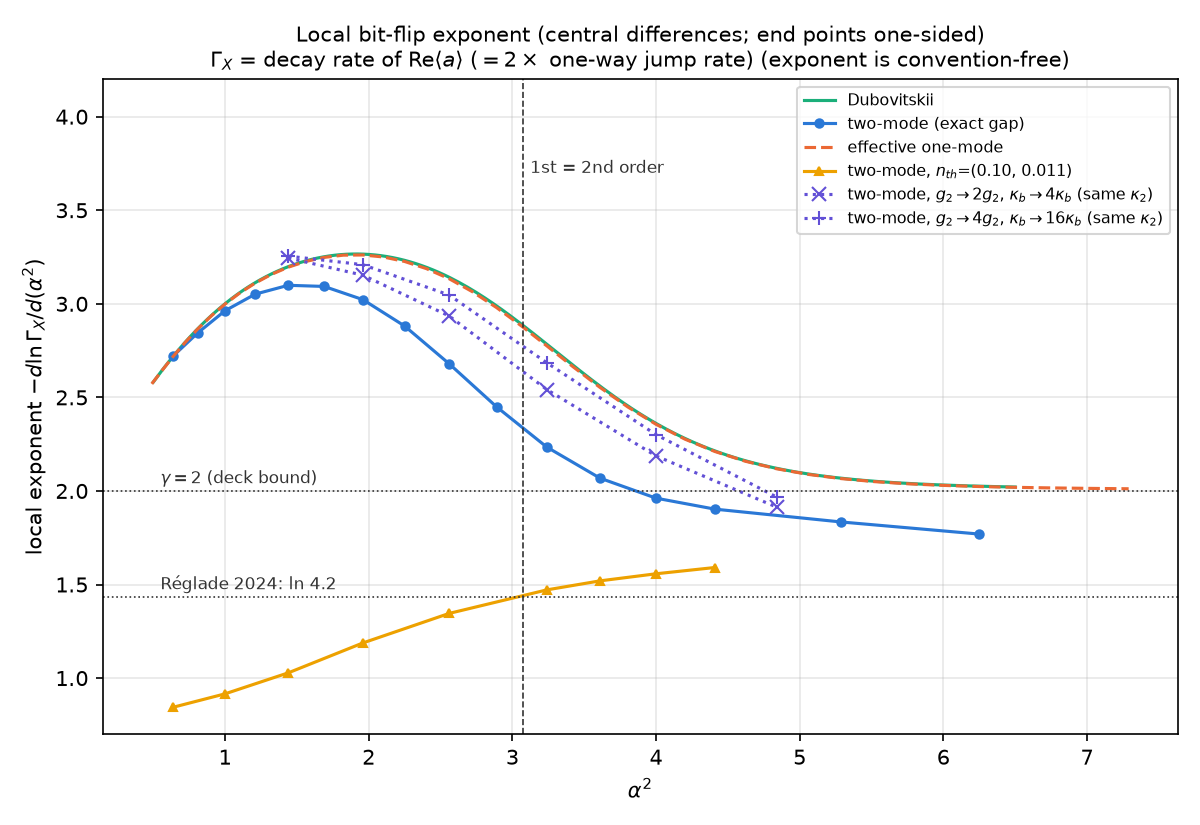

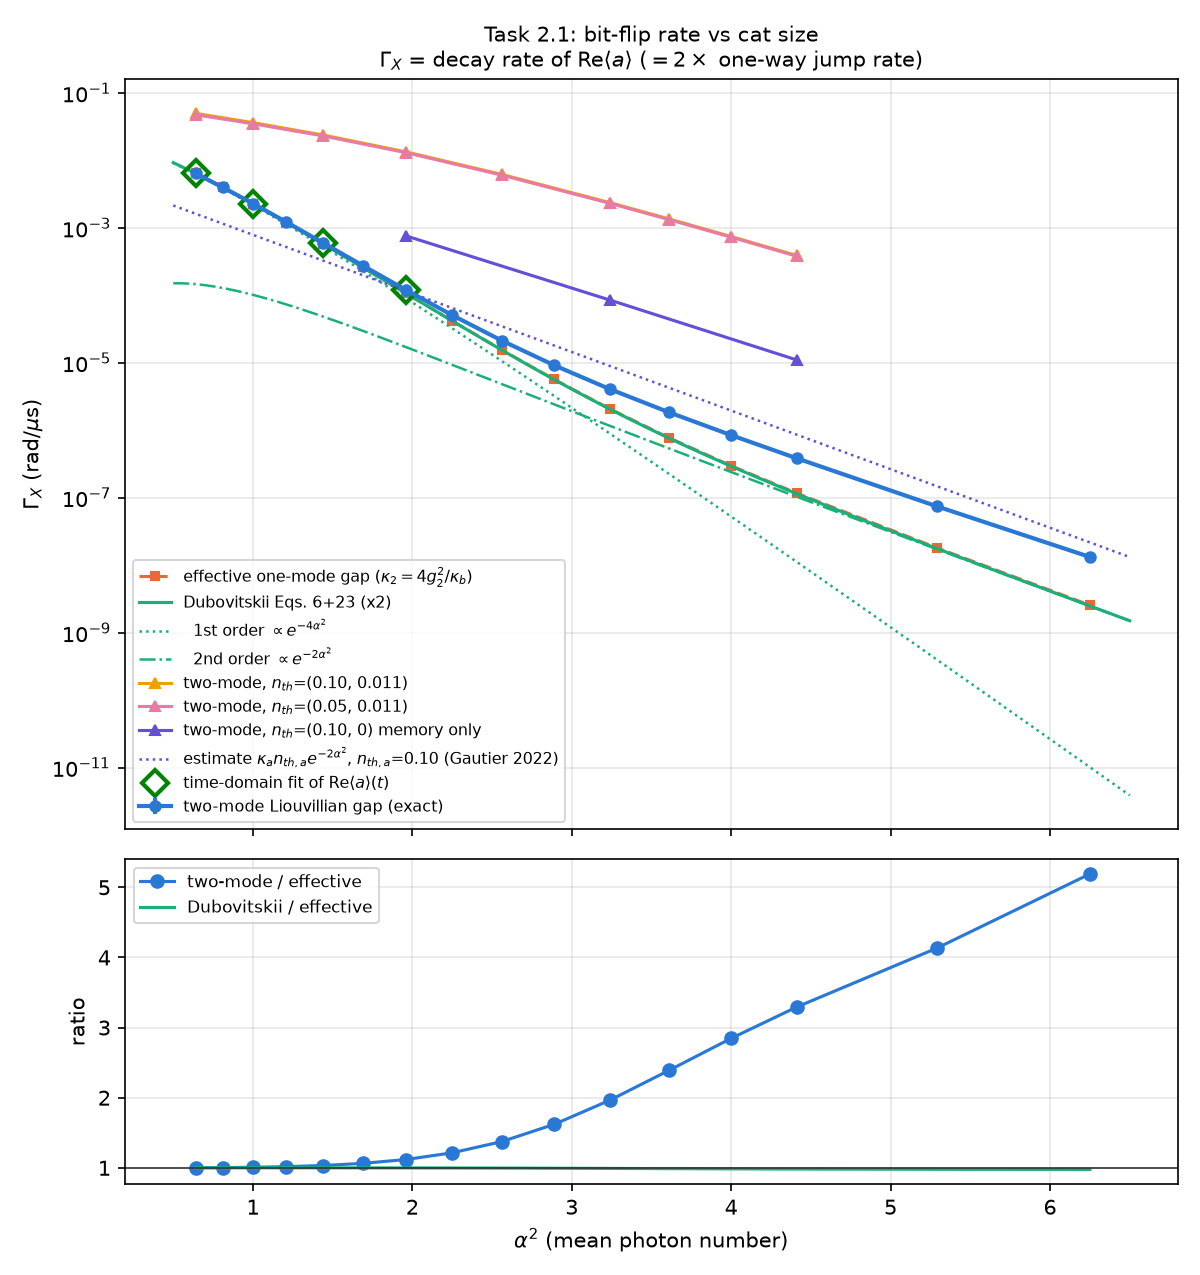

In [3]:
analysis = load("task21/analysis.json")
print(f"{'window':>12} {'gamma (plain)':>14} {'gamma (alpha^2 prefactor)':>26}")
for fit in analysis["fits"]["two_mode"].values():
    lo, hi = fit["window_alpha"]
    print(f"{lo:5.1f}-{hi:<5.1f}  {fit['p0']['gamma']:14.2f} {fit['p1']['gamma']:26.2f}")
show("task21_local_exponent")
show("task21_rates")

## 2.2 Phase-flip time

Live: the slowest nonzero rate of the parity-even sector against $2\kappa_a\alpha^2$.

alpha=1.4: Gamma_Z = 0.228381 /us, ratio to 2 kappa_a alpha^2 = 0.9970


alpha=1.8: Gamma_Z = 0.377813 /us, ratio to 2 kappa_a alpha^2 = 0.9978


alpha=2.1: Gamma_Z = 0.514558 /us, ratio to 2 kappa_a alpha^2 = 0.9984
spectral_alpha_ge_1.4: slope / 2 kappa_a = 0.99987
thermal_spectral_alpha_ge_1.4: slope / 2 kappa_a = 1.20049


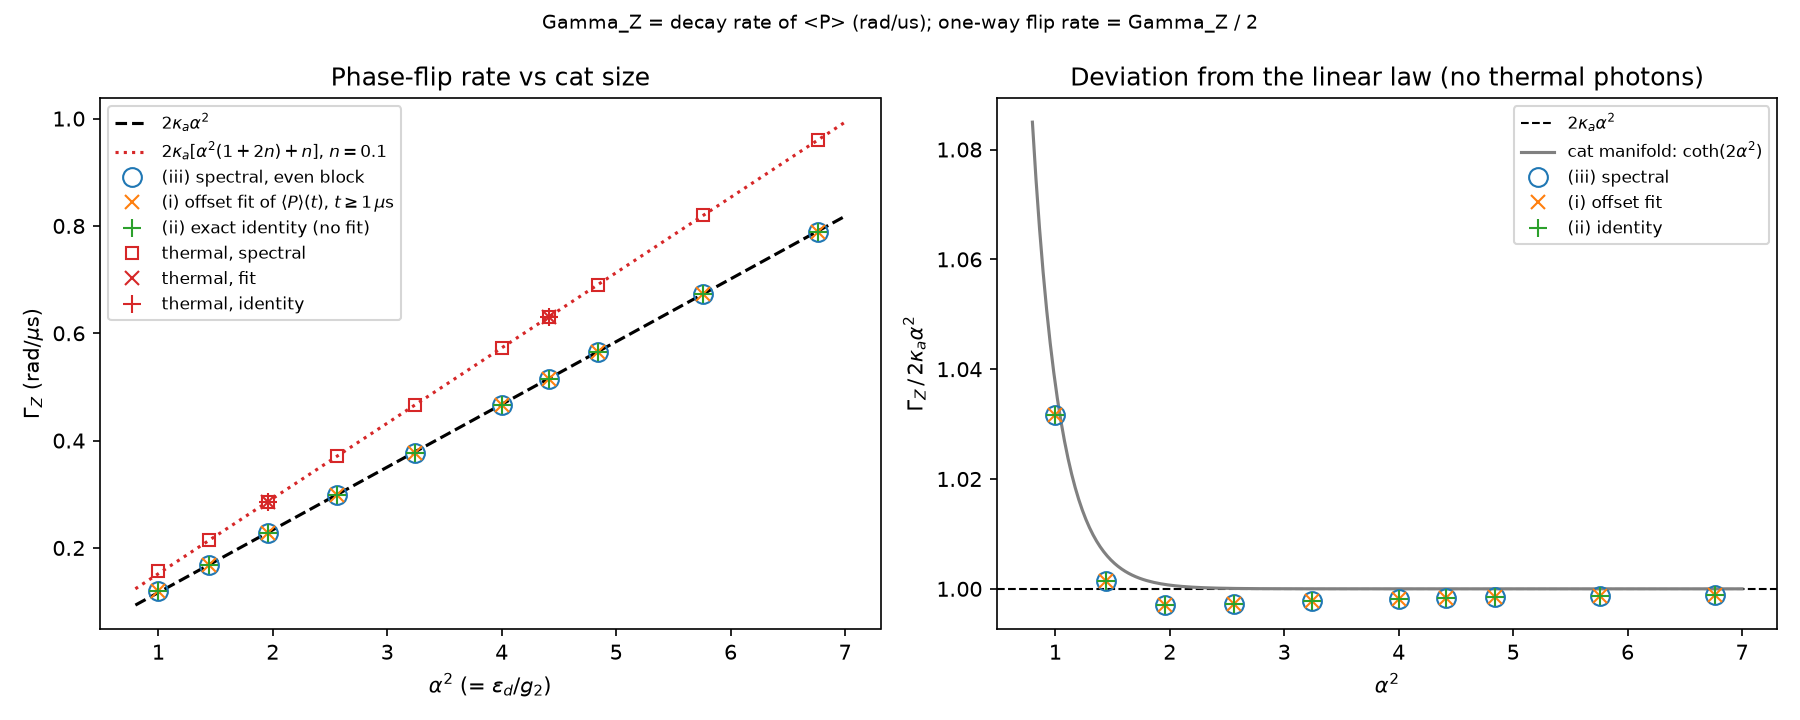

In [4]:
for alpha in (1.4, 1.8, 2.1):
    p = replace(P, alpha=alpha)
    na = int(np.ceil(alpha**2 + 6 * alpha)) + 8
    rate = phase_flip_rate(p, FockTruncation(na, 5))
    ratio = rate / (2 * P.kappa_a * alpha**2)
    print(f"alpha={alpha}: Gamma_Z = {rate:.6f} /us, ratio to 2 kappa_a alpha^2 = {ratio:.4f}")
slopes = load("task22/task22_phaseflip.json")["slopes"]
for key in ("spectral_alpha_ge_1.4", "thermal_spectral_alpha_ge_1.4"):
    print(f"{key}: slope / 2 kappa_a = {slopes[key]['slope_over_2kappa_a']:.5f}")
show("task22_rates")

## 2.3 Readout through the buffer

Live: add $H_Z = \varepsilon_Z(a^\dagger + a)$ with $\varepsilon_Z = 0.3 g_2$ at α = 2.1, start from
$|\pm\alpha\rangle|0\rangle$, and compare $\langle b\rangle(t)$ with the linear theory (plateau
$\mp\varepsilon_Z/(2\alpha g_2)$, ringing at $2\alpha g_2$).

sign +1: 2.3 s
  plateau: full -0.07129, linear -0.07143


sign -1: 0.3 s
  plateau: full +0.07129, linear +0.07143


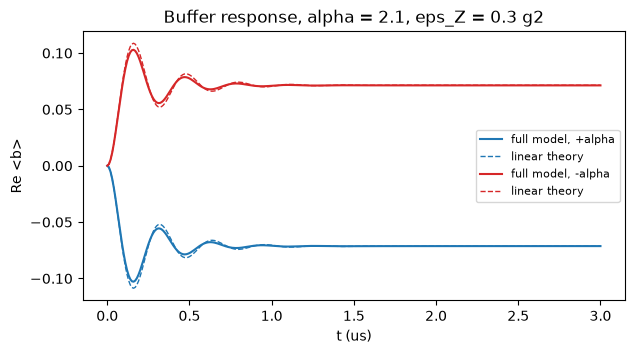

ringing 3.138 MHz
linear 1% settling 1.131 us


In [5]:
EPS_Z = 0.3 * P.g2
tsave = np.linspace(0.0, 3.0, 301)
fig, ax = plt.subplots(figsize=(7, 3.5))
for sign, color in ((+1, "C0"), (-1, "C3")):
    t, b = timed(f"sign {sign:+d}", lambda: simulate_buffer_response(P, 24, 5, EPS_Z, sign, tsave))
    linear = LinearBufferResponse.from_params(P, EPS_Z, sign)
    ax.plot(t, np.real(b), color=color, label=f"full model, {'+' if sign > 0 else '-'}alpha")
    ax.plot(t, linear.mean_b(t), color=color, ls="--", lw=1, label="linear theory")
    print(f"  plateau: full {np.real(b[-1]):+.5f}, linear {linear.steady_state:+.5f}")
ax.set(xlabel="t (us)", ylabel="Re <b>", title="Buffer response, alpha = 2.1, eps_Z = 0.3 g2")
ax.legend(fontsize=8)
plt.show()
print(f"ringing {linear.ringing_frequency_mhz:.3f} MHz")
print(f"linear 1% settling {linear.settling_time():.3f} us")

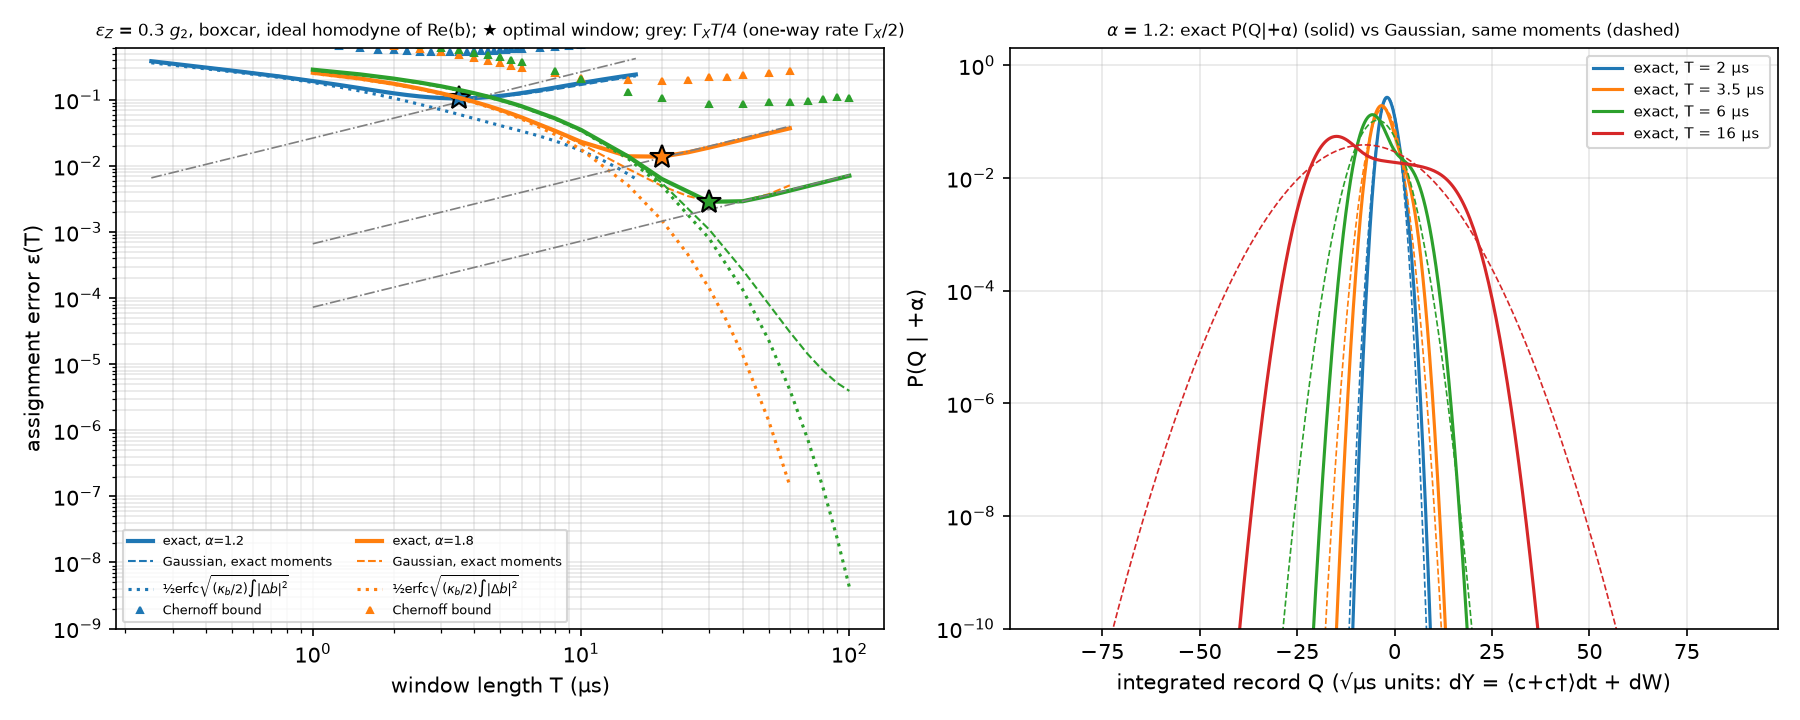

In [6]:
show("task23_error_vs_T")

## 2.4(a) Circuit terms from the ATS Hamiltonian

Symbolic normal ordering (`catqubit.normal_order`), checked against an all-orders Fock-space
computation. Values in MHz (×2π convention as in the prompt).

        g2  a^2 b^dag                              -0.72811 MHz
   Delta_a  a^dag a                                +0.9291 MHz
   Delta_b  b^dag b                                +23.056 MHz
       K_a  (K_a/2) a^dag^2 a^2                    -0.0049414 MHz
       K_b  (K_b/2) b^dag^2 b^2                    -2.673 MHz
    chi_ab  a^dag a b^dag b                        -0.1995 MHz
     g2_nb  a^2 b^dag^2 b (= a^2 b^dag . b^dag b)  +0.032765 MHz
  eps_Z_nb  a^dag b^dag b                          (relative to eps_Z, see JSON)
 pt_a_bdag  a b^dag (pump x tone)                  (relative to eps_Z, see JSON)


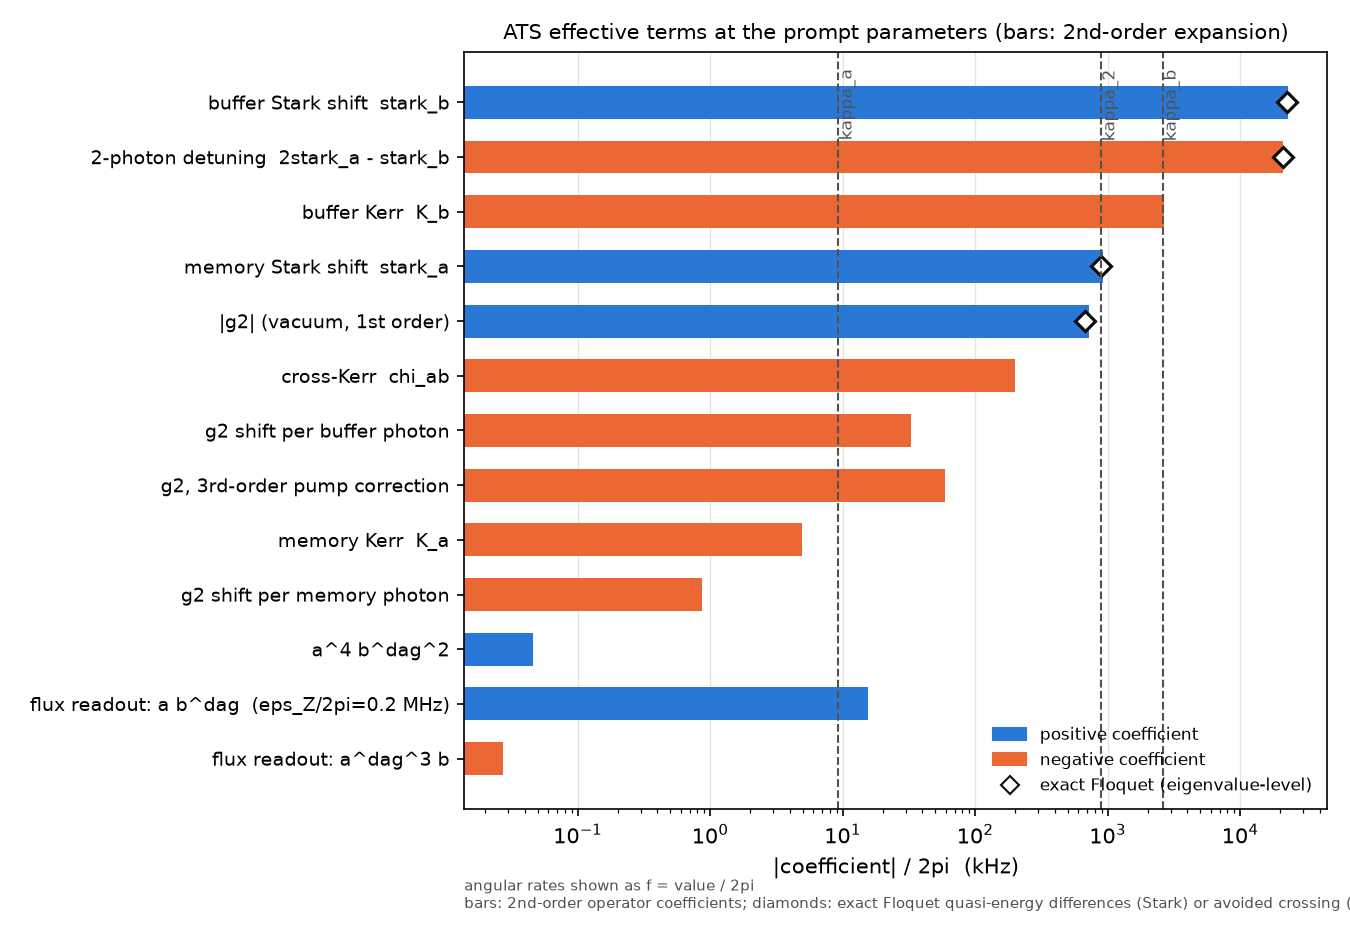

In [7]:
terms = load("task24a/symbolic_terms.json")["terms"]
for key in ("g2", "Delta_a", "Delta_b", "K_a", "K_b", "chi_ab", "g2_nb", "eps_Z_nb", "pt_a_bdag"):
    entry = terms[key]
    value = entry.get("value_mhz")
    shown = f"{value:+.5g} MHz" if value is not None else "(relative to eps_Z, see JSON)"
    print(f"{key:>10}  {entry['operator']:<38} {shown}")
show("task24a_terms")

## 2.4(b) Contrast against bit flips

Live: the exact second-order coefficient $c_2$ in
$\Gamma_X(\varepsilon_Z) = \Gamma_X(0) + c_2\varepsilon_Z^2$ at α = 1.4, from linear response of
the slowest Liouvillian eigenvalue. Contrast is $|\Delta b| = \varepsilon_Z/(\alpha g_2)$ and the
measurement rate is $\kappa_b|\Delta b|^2/2$, so the flips per unit of measurement rate,
$c_2 g_2^2\alpha^2/(\kappa_b/2)$, do not depend on $\varepsilon_Z$.

c2 at alpha=1.4: 0.9 s
Gamma_X(0) = 1.2021e-04 /us, c2 = 0.01611 us
flips per unit measurement rate = 0.0888
  study alpha=1.2: rate0 5.999e-04, c2 0.04457
  study alpha=1.4: rate0 1.202e-04, c2 0.01611
  study alpha=1.6: rate0 2.141e-05, c2 0.004696
  study alpha=1.8: rate0 4.067e-06, c2 0.001131
  study alpha=2.1: rate0 3.850e-07, c2 9.909e-05


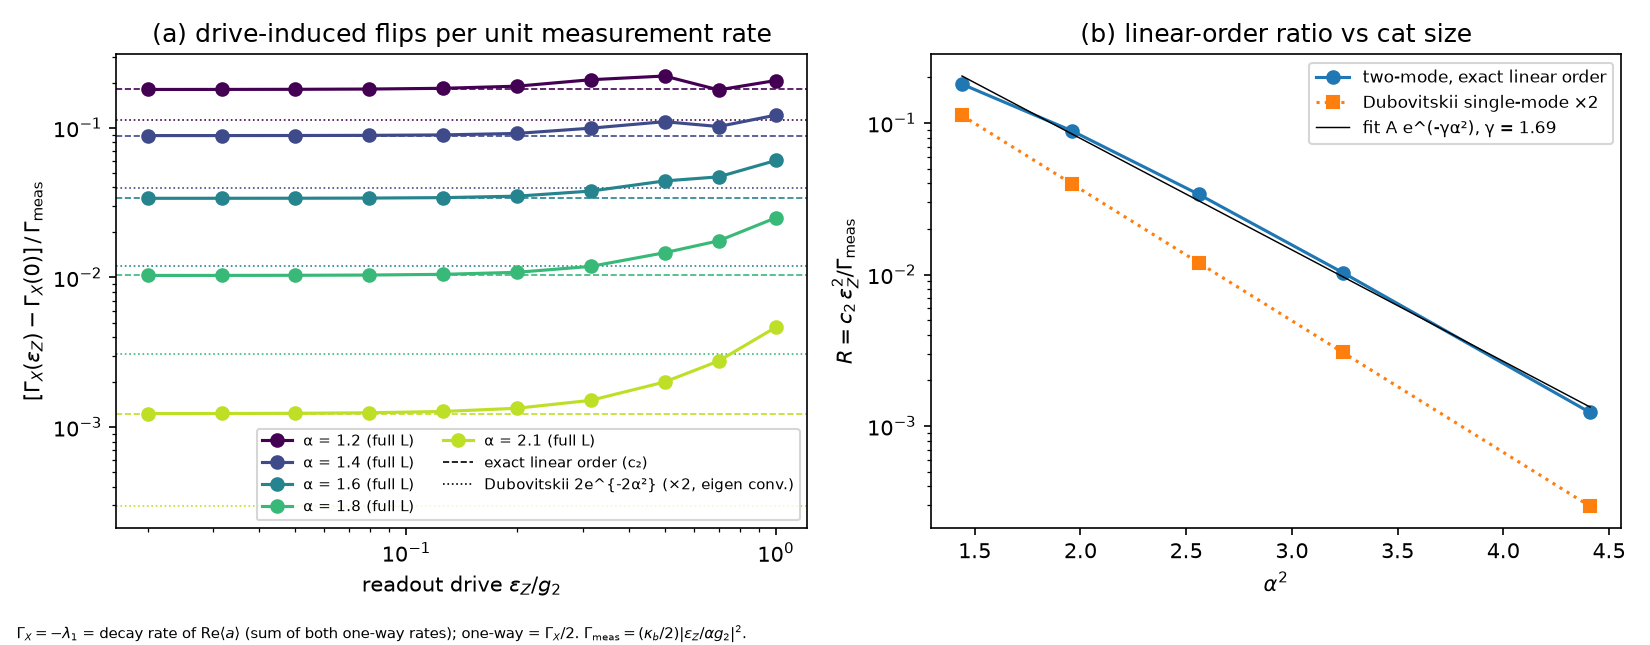

In [8]:
alpha = 1.4
p = replace(P, alpha=alpha)
response = timed("c2 at alpha=1.4", lambda: drive_rate_coefficient(
    HamiltonianTerms.from_params(p), Dissipation.from_params(p), FockTruncation(20, 5, 2, 6.0)))
ratio = response.coefficient * P.g2**2 * alpha**2 / (0.5 * P.kappa_b)
print(f"Gamma_X(0) = {response.rate0:.4e} /us, c2 = {response.coefficient:.5f} us")
print(f"flips per unit measurement rate = {ratio:.4f}")
for key, row in load("task24/tradeoff_r9.json")["per_alpha"].items():
    base = row["linear_response"]["truncations"]["base"]
    print(f"  study alpha={key}: rate0 {base['rate0']:.3e}, c2 {base['c2']:.4g}")
show("task24_tradeoff_ratio")

## 2.4(c–d) Strategies to improve readout

1. **Adaptive stopping with an erasure flag** (HMM filter + sequential test): the largest gain.
   *Caveat:* its flip model is illustrative and 4× below the 2.4(b) rate at 0.3 g₂.
2. **Shaped readout pulse** scored against the exact drive kernel: ×2.7 lower flip cost at α = 1.4.
   A quasi-static flip model underestimates the cost of shaped pulses.
3. **Squeezed buffer bath** (hypothesis test): squeezing the signal quadrature makes things worse;
   squeezing the other quadrature helps a little.

| alpha | eps_Z/g2 | eta | Gamma_X (rad/us) | mu^2 (1/us) | target p_X(T) | window box/MF/HMM (us) | HMM+SPRT cap: p_err, mean T, speedup | +freeze | +freeze+erasure |
| 2.1 | 0.3 | 1.0 | 4.96e-05 | 0.333 | 5.21e-04 | n/a / n/a / 41.6 | A=9.0: 3.2e-04, T=21 (q99 45), xn/a | A=10.5: 3.0e-04, T=19.9 (q99 43.2), xn/a | A=9.0: 1.9e-04, T=15.6 (q99 40.3), xn/a, eras 1.8e-03 (a_e=0.0, theta=0.02) |
| 2.1 | 0.3 | 0.6 | 4.96e-05 | 0.2 | 8.53e-04 | n/a / n/a / 69.3 | A=8.5: 6.3e-04, T=34.4 (q99 75), xn/a | A=10.0: 6.1e-04, T=32 (q99 70.1), xn/a | A=8.5: 3.4e-04, T=24.8 (q99 65.2), xn/a, eras 3.1e-03 (a_e=0.0, theta=0.02) |


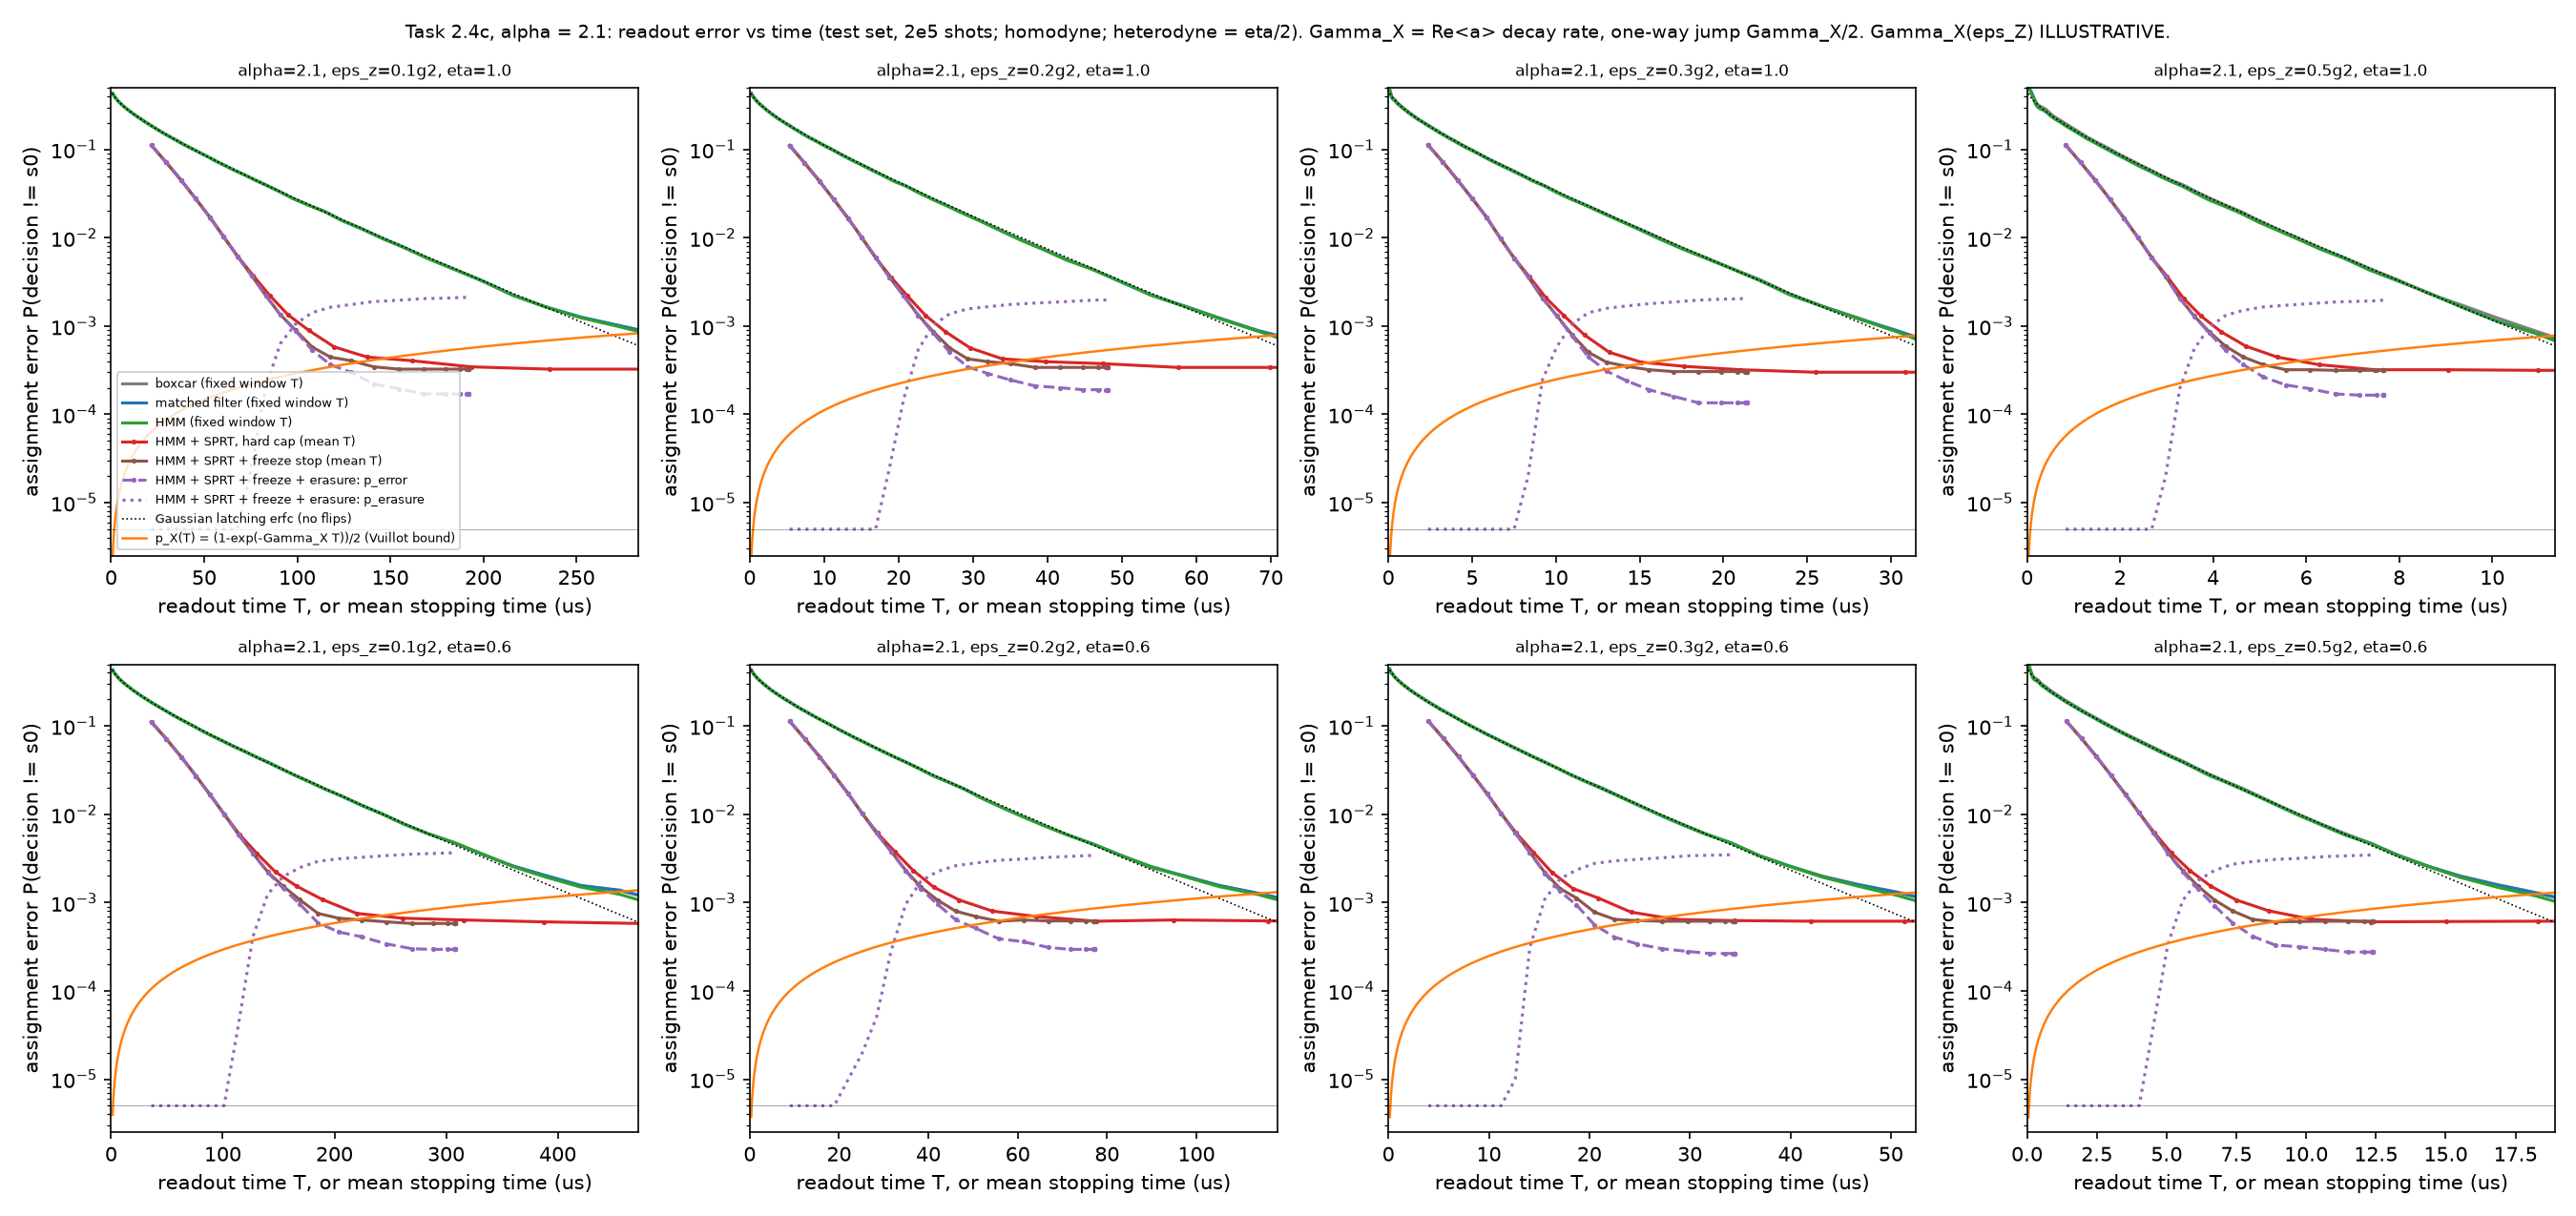

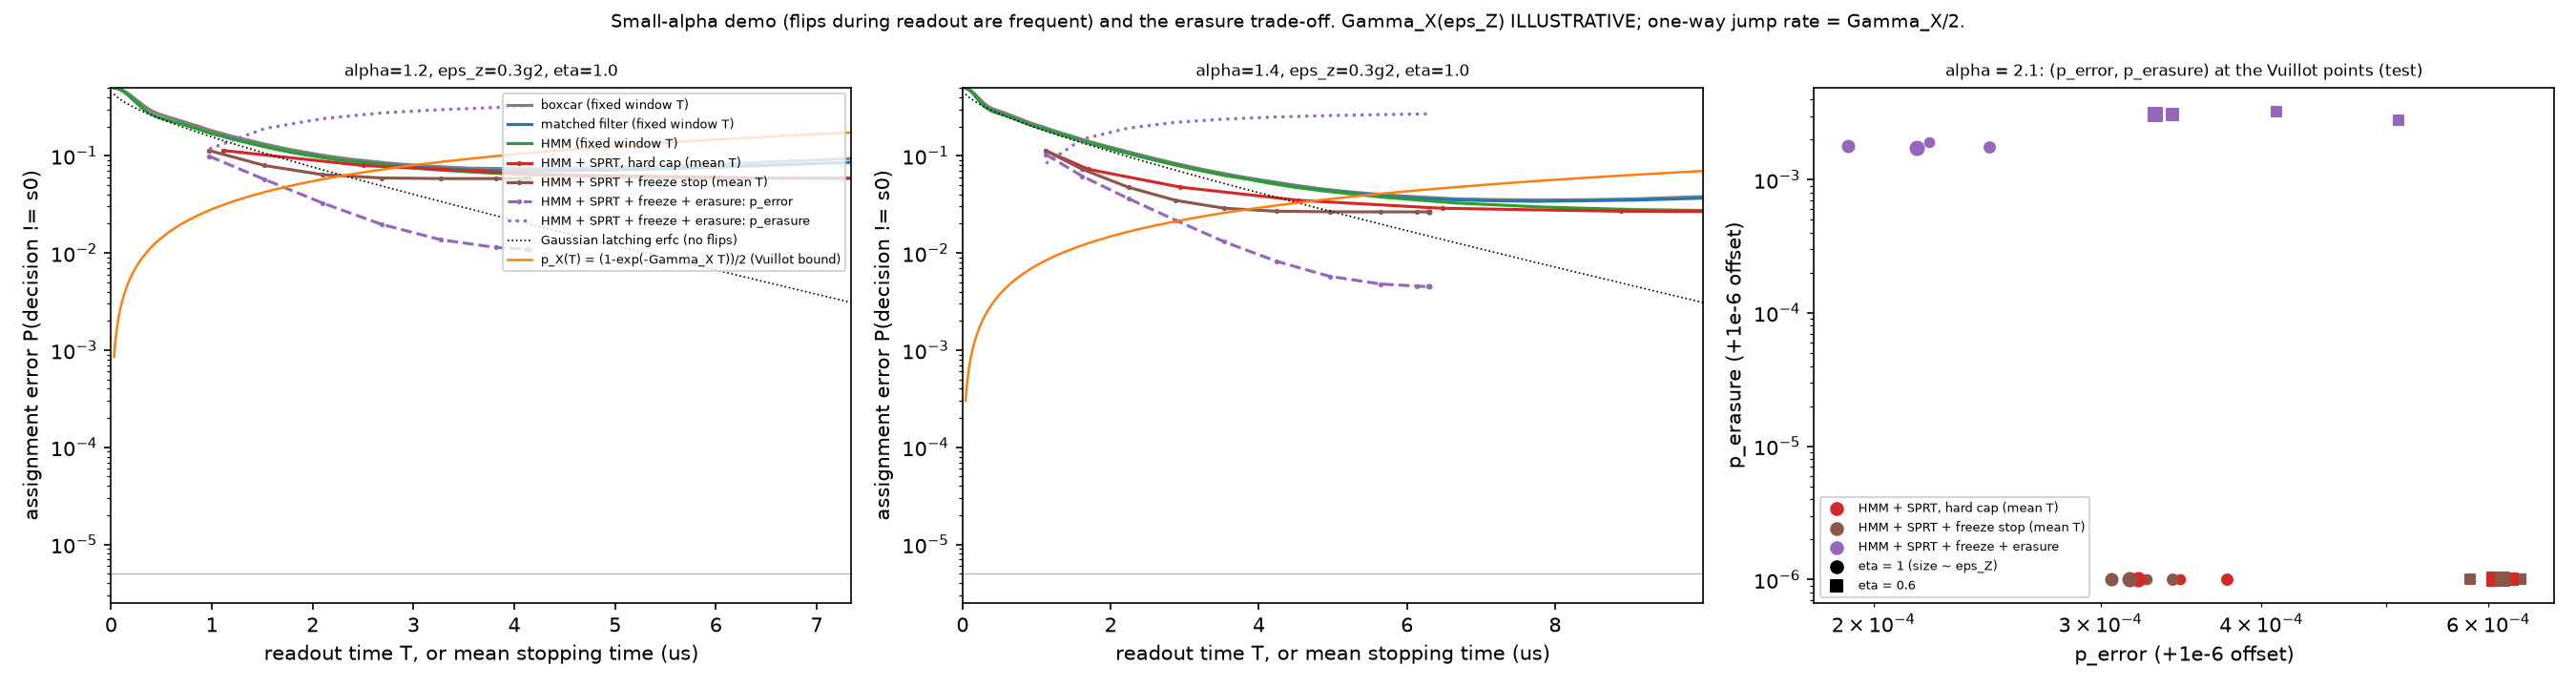

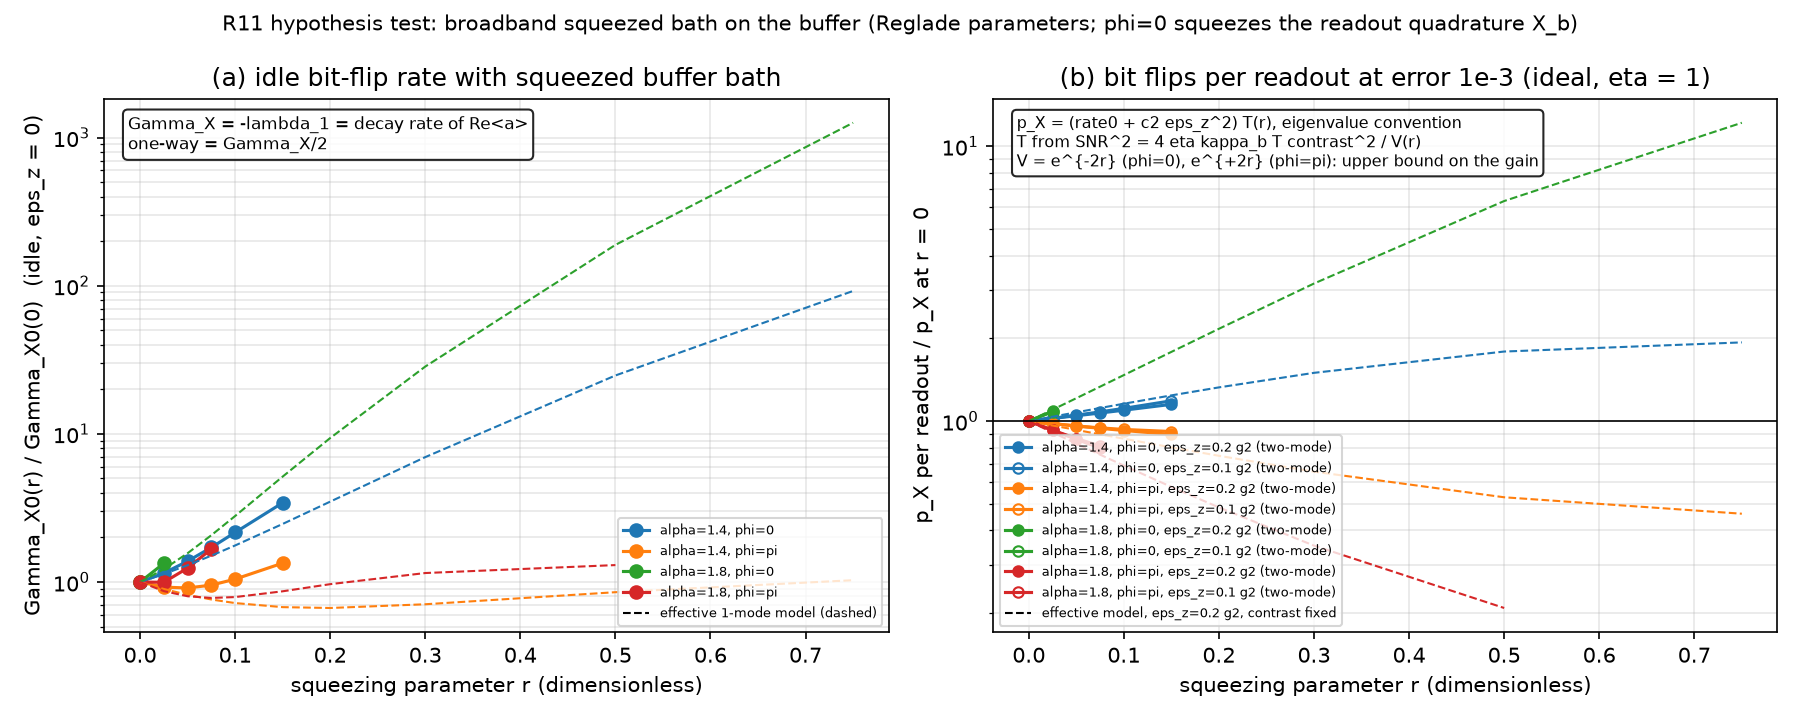

In [9]:
summary = (RESULTS / "task24c/summary.md").read_text().splitlines()
rows = [line for line in summary if line.startswith(("| alpha", "| 2.1 | 0.3"))]
print("\n".join(rows))
show("task24c_error_vs_time")
show("task24c_erasure")
show("task24_squeezing")